# Project 27: Benchmark pandas vs Polars vs DuckDB

1 juta baris produksi sintetis (`01_generate_raw.py --big 1000000`); tiap tugas diulang 3 kali, dilaporkan median. Waktu bergantung pada mesin.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation', '4-automation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

In [2]:
display(R('benchmark_env.csv')); b = R('benchmark.csv'); b

,python,platform,cpu_count,pandas,polars,duckdb
0,3.13.18,Linux-6.18.44-fc-v185-x86_64-with-glibc2.39,2,3.0.5,2.1.0,2.0.0


,engine,task,median_s,min_s,max_s,repeats,speedup_vs_pandas,rows
0,pandas,baca CSV saja,0.5342,0.5073,0.5854,3,1.0000,1000000
1,pandas,baca + agregasi KPI,0.6749,0.6252,0.7012,3,1.0000,1000000
2,Polars,baca CSV saja,0.0824,0.0755,0.1881,3,6.4861,1000000
3,Polars,baca + agregasi KPI,0.2638,0.2056,0.2785,3,2.5581,1000000
4,DuckDB,baca CSV saja,0.1294,0.1293,0.1646,3,4.1285,1000000
5,DuckDB,baca + agregasi KPI,0.2199,0.2199,0.2382,3,3.0686,1000000


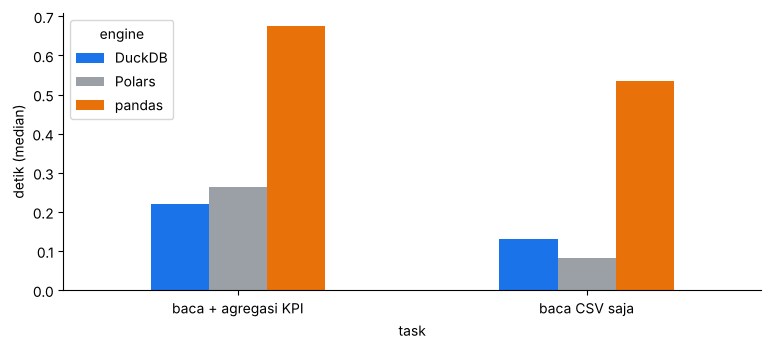

In [3]:
p = b.pivot(index='task', columns='engine', values='median_s'); p.plot.bar(color=[BLUE, GREY, ORANGE], rot=0); plt.ylabel('detik (median)'); plt.show()